In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(context='notebook', style='darkgrid', palette='bright',)

In [141]:
PATH = Path('/Users/alp/Projects/House Prices/data')
train = pd.read_csv(PATH / 'train.csv', index_col='Id')
test = pd.read_csv(PATH / 'test.csv', index_col='Id')
train.shape

(1460, 80)

In [26]:
train.describe()

,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,46.549315,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,161.319273,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,0.000000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,0.000000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,1474.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [10]:
train.columns

Index(['MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street', 'Alley',
       'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope',
       'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle',
       'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'RoofStyle',
       'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'MasVnrArea',
       'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond',
       'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1', 'BsmtFinType2',
       'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating', 'HeatingQC',
       'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF',
       'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath',
       'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual', 'TotRmsAbvGrd',
       'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType', 'GarageYrBlt',
       'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual', 'GarageCond',
       'PavedDrive', 'Wo

In [12]:
print(train.dtypes)

MSSubClass         int64
MSZoning             str
LotFrontage      float64
LotArea            int64
Street               str
                  ...   
MoSold             int64
YrSold             int64
SaleType             str
SaleCondition        str
SalePrice          int64
Length: 80, dtype: object


In [13]:
train.SalePrice.describe()

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

<Axes: xlabel='SalePrice', ylabel='Count'>

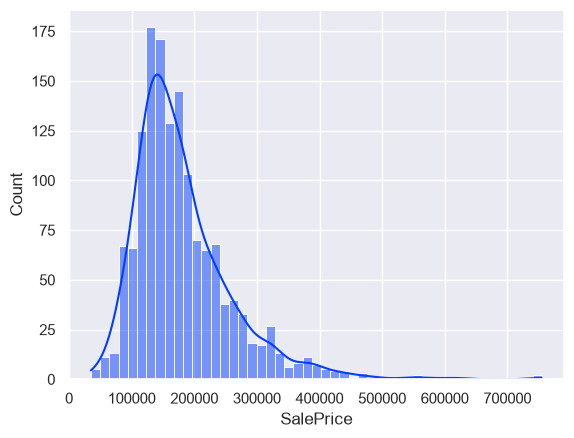

In [ ]:
sns.histplot(train, x='SalePrice', kde=True)

In [ ]:
print("Skewness: %f" % train['SalePrice'].skew())
print("Kurtosis: %f" % train['SalePrice'].kurt())

Skewness: 1.882876
Kurtosis: 6.536282


<Axes: >

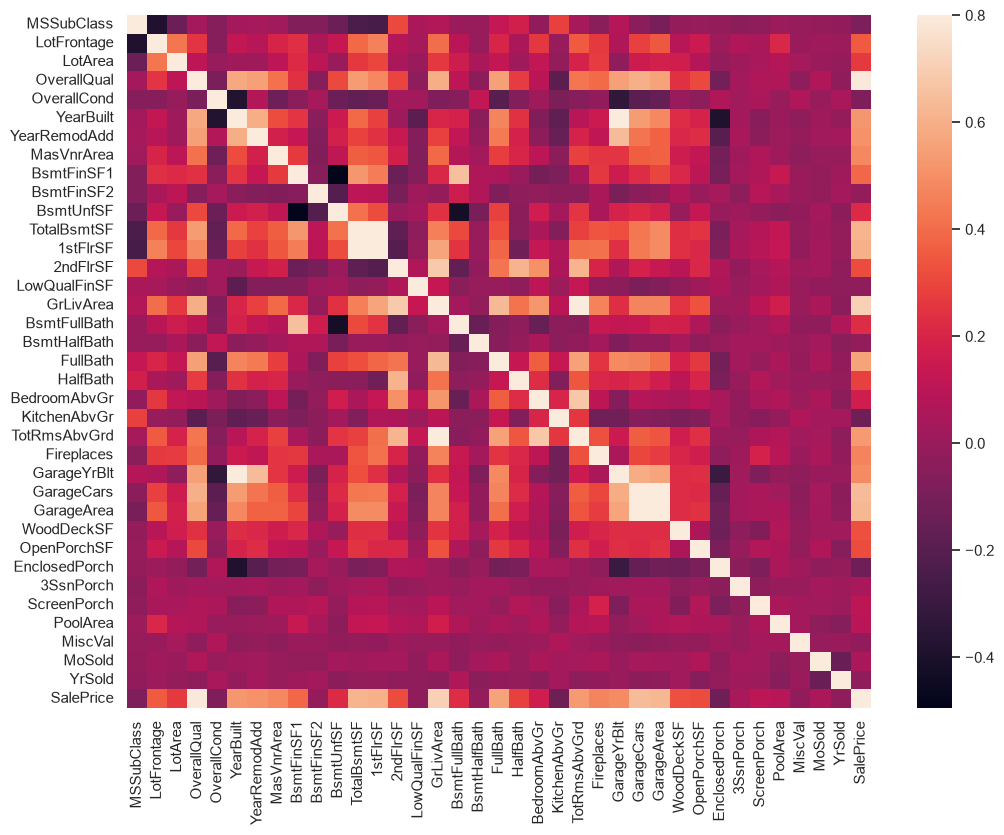

In [45]:
# Correlation Matrix
corrmat = train.corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(corrmat, vmax=.8)

In [60]:
# Top k highly correlated features to SalePrice
k = 10
corrmat['SalePrice'].drop('SalePrice').abs().sort_values(ascending=False).head(k)

OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
Name: SalePrice, dtype: float64

['1stFlrSF', 'TotalBsmtSF', 'GarageArea', 'GarageCars', 'GrLivArea', 'OverallQual']


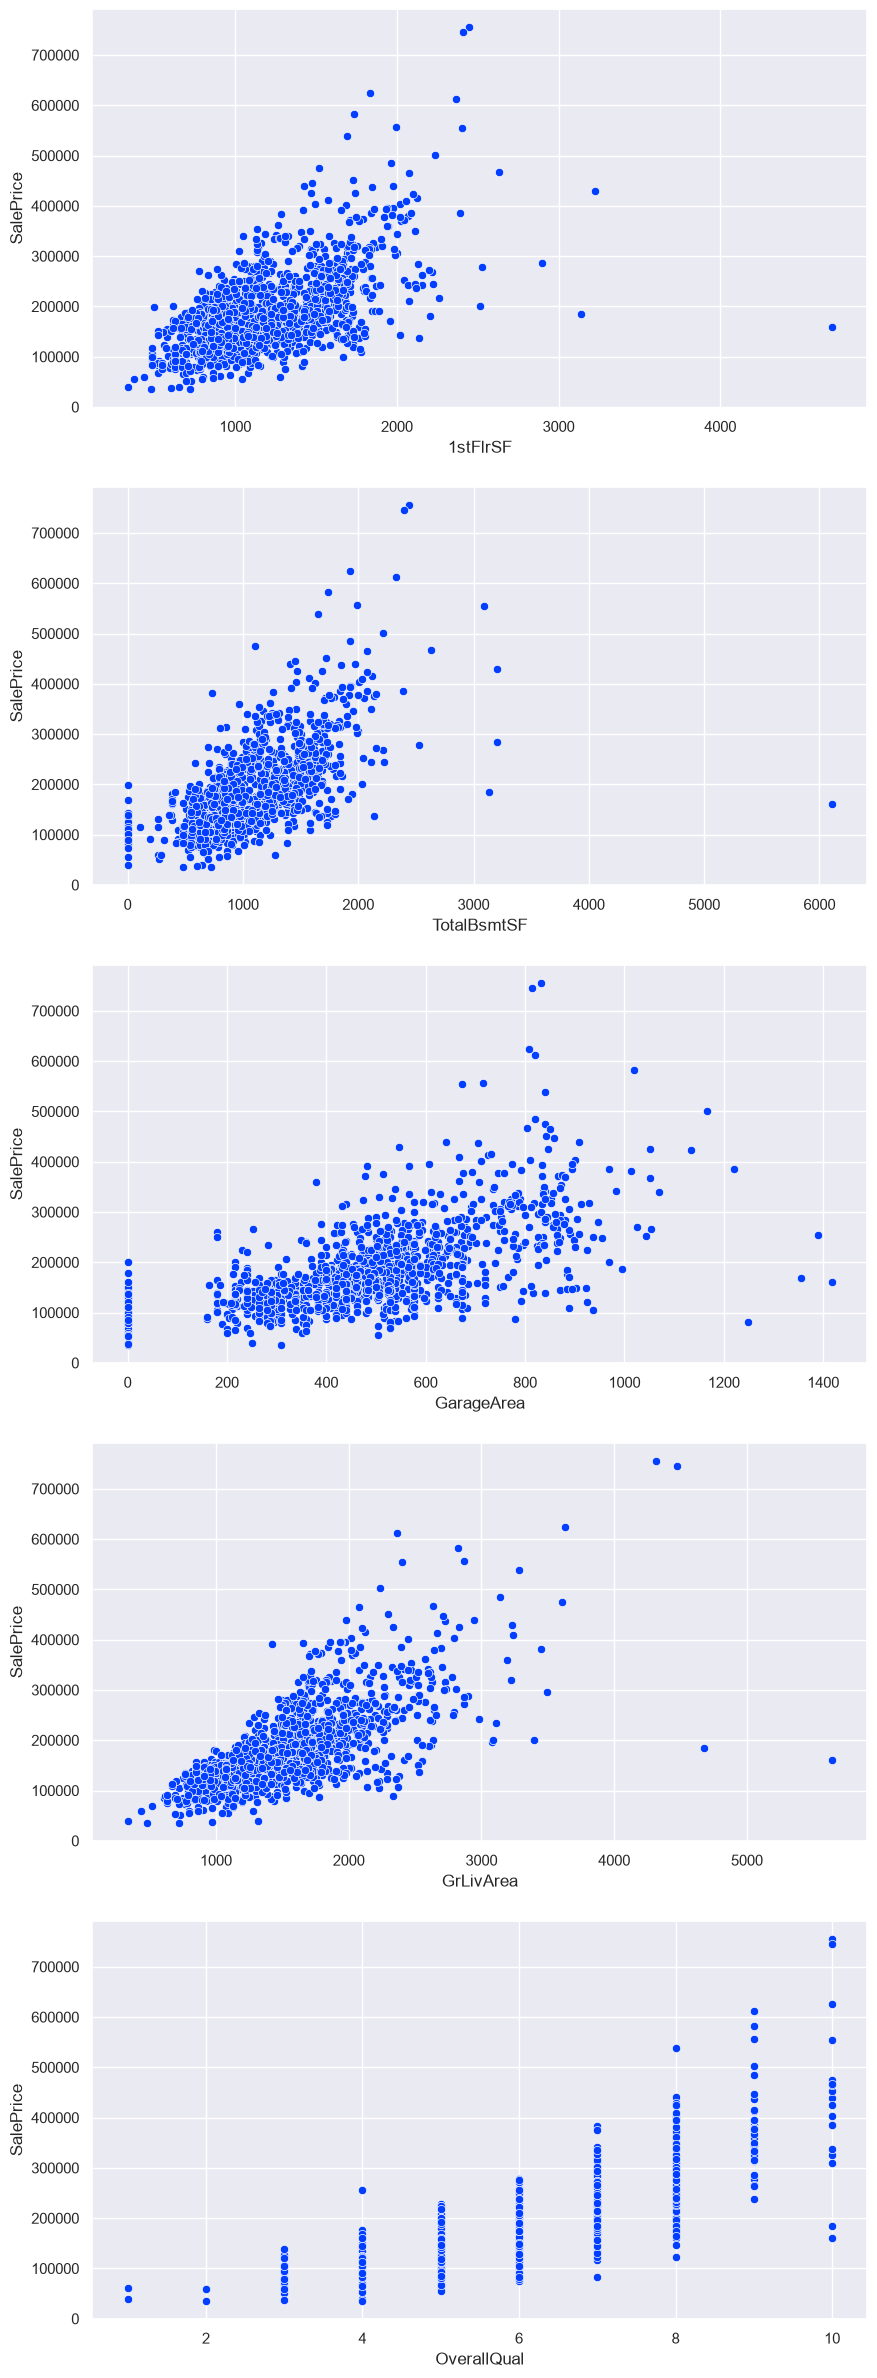

In [64]:
high_corr_feats = corrmat['SalePrice'].drop('SalePrice').abs().sort_values().tail(6).index.to_list()
print(high_corr_feats)
del high_corr_feats[3] # remove GarageCars since it is very similar to GarageArea


fig, ax = plt.subplots(5, 1, figsize=(10, 30))

for i, feat in enumerate(high_corr_feats):
    sns.scatterplot(train, x=feat, y='SalePrice', ax=ax[i])


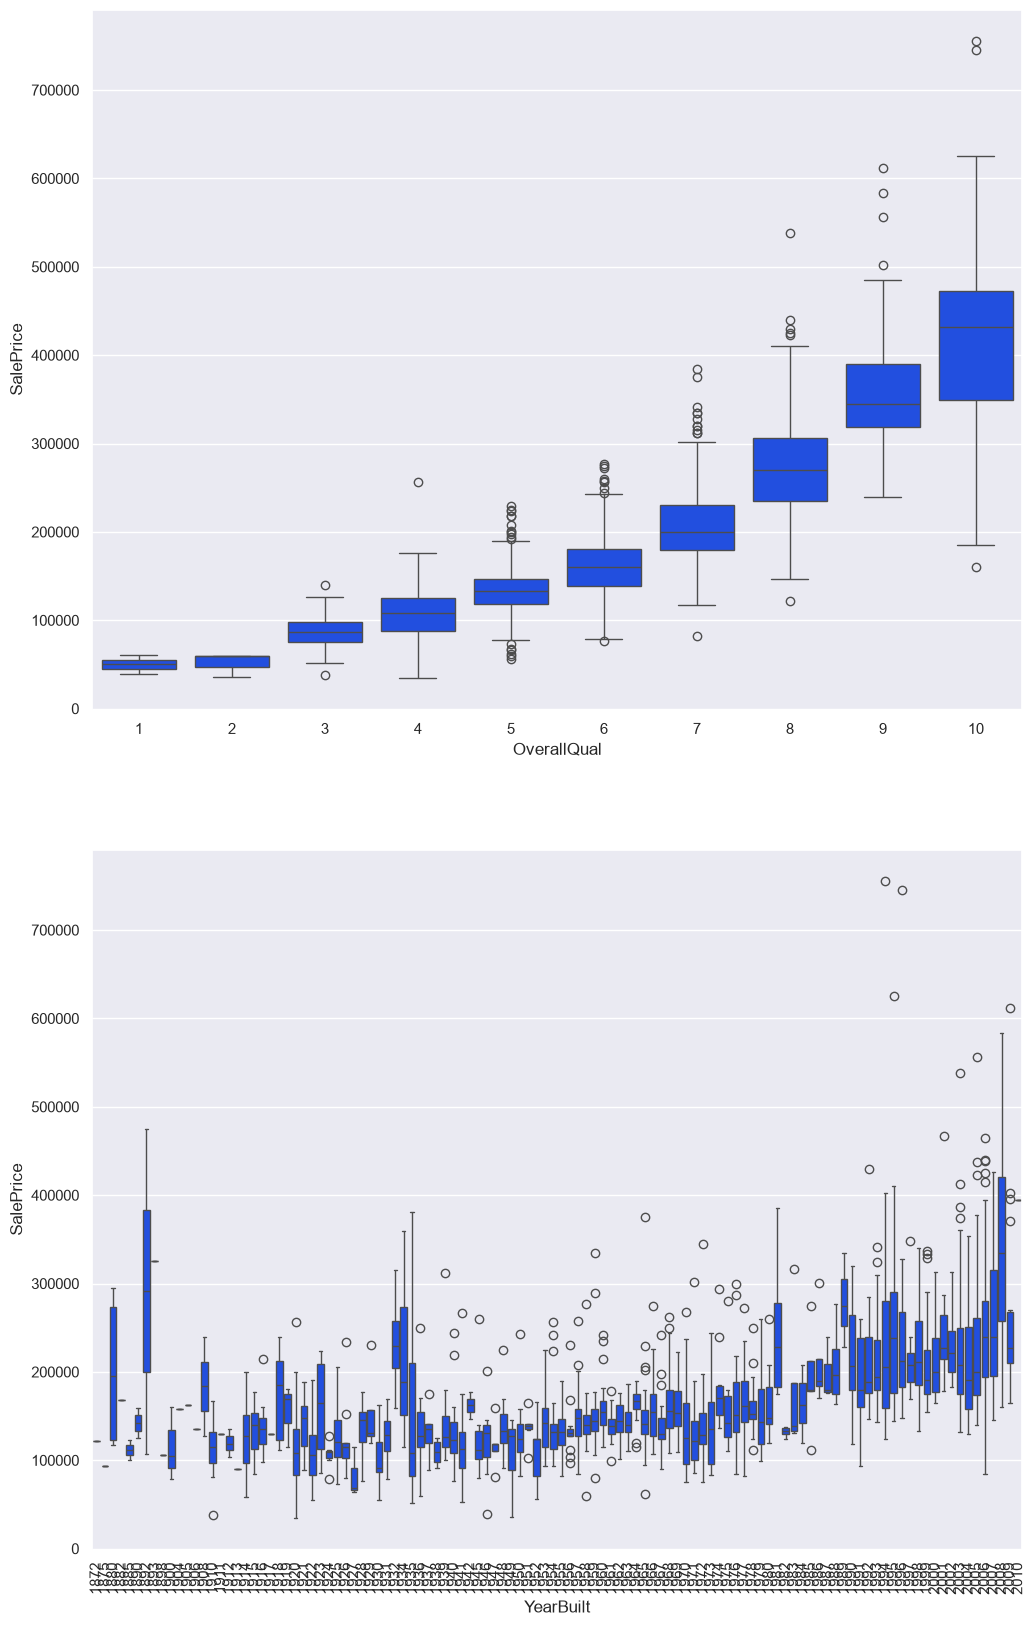

In [67]:
fig, ax = plt.subplots(2, 1, figsize=(12,20))

sns.boxplot(train, x='OverallQual', y='SalePrice', ax=ax[0])
sns.boxplot(train, x='YearBuilt', y='SalePrice', ax=ax[1])
plt.xticks(rotation=90);

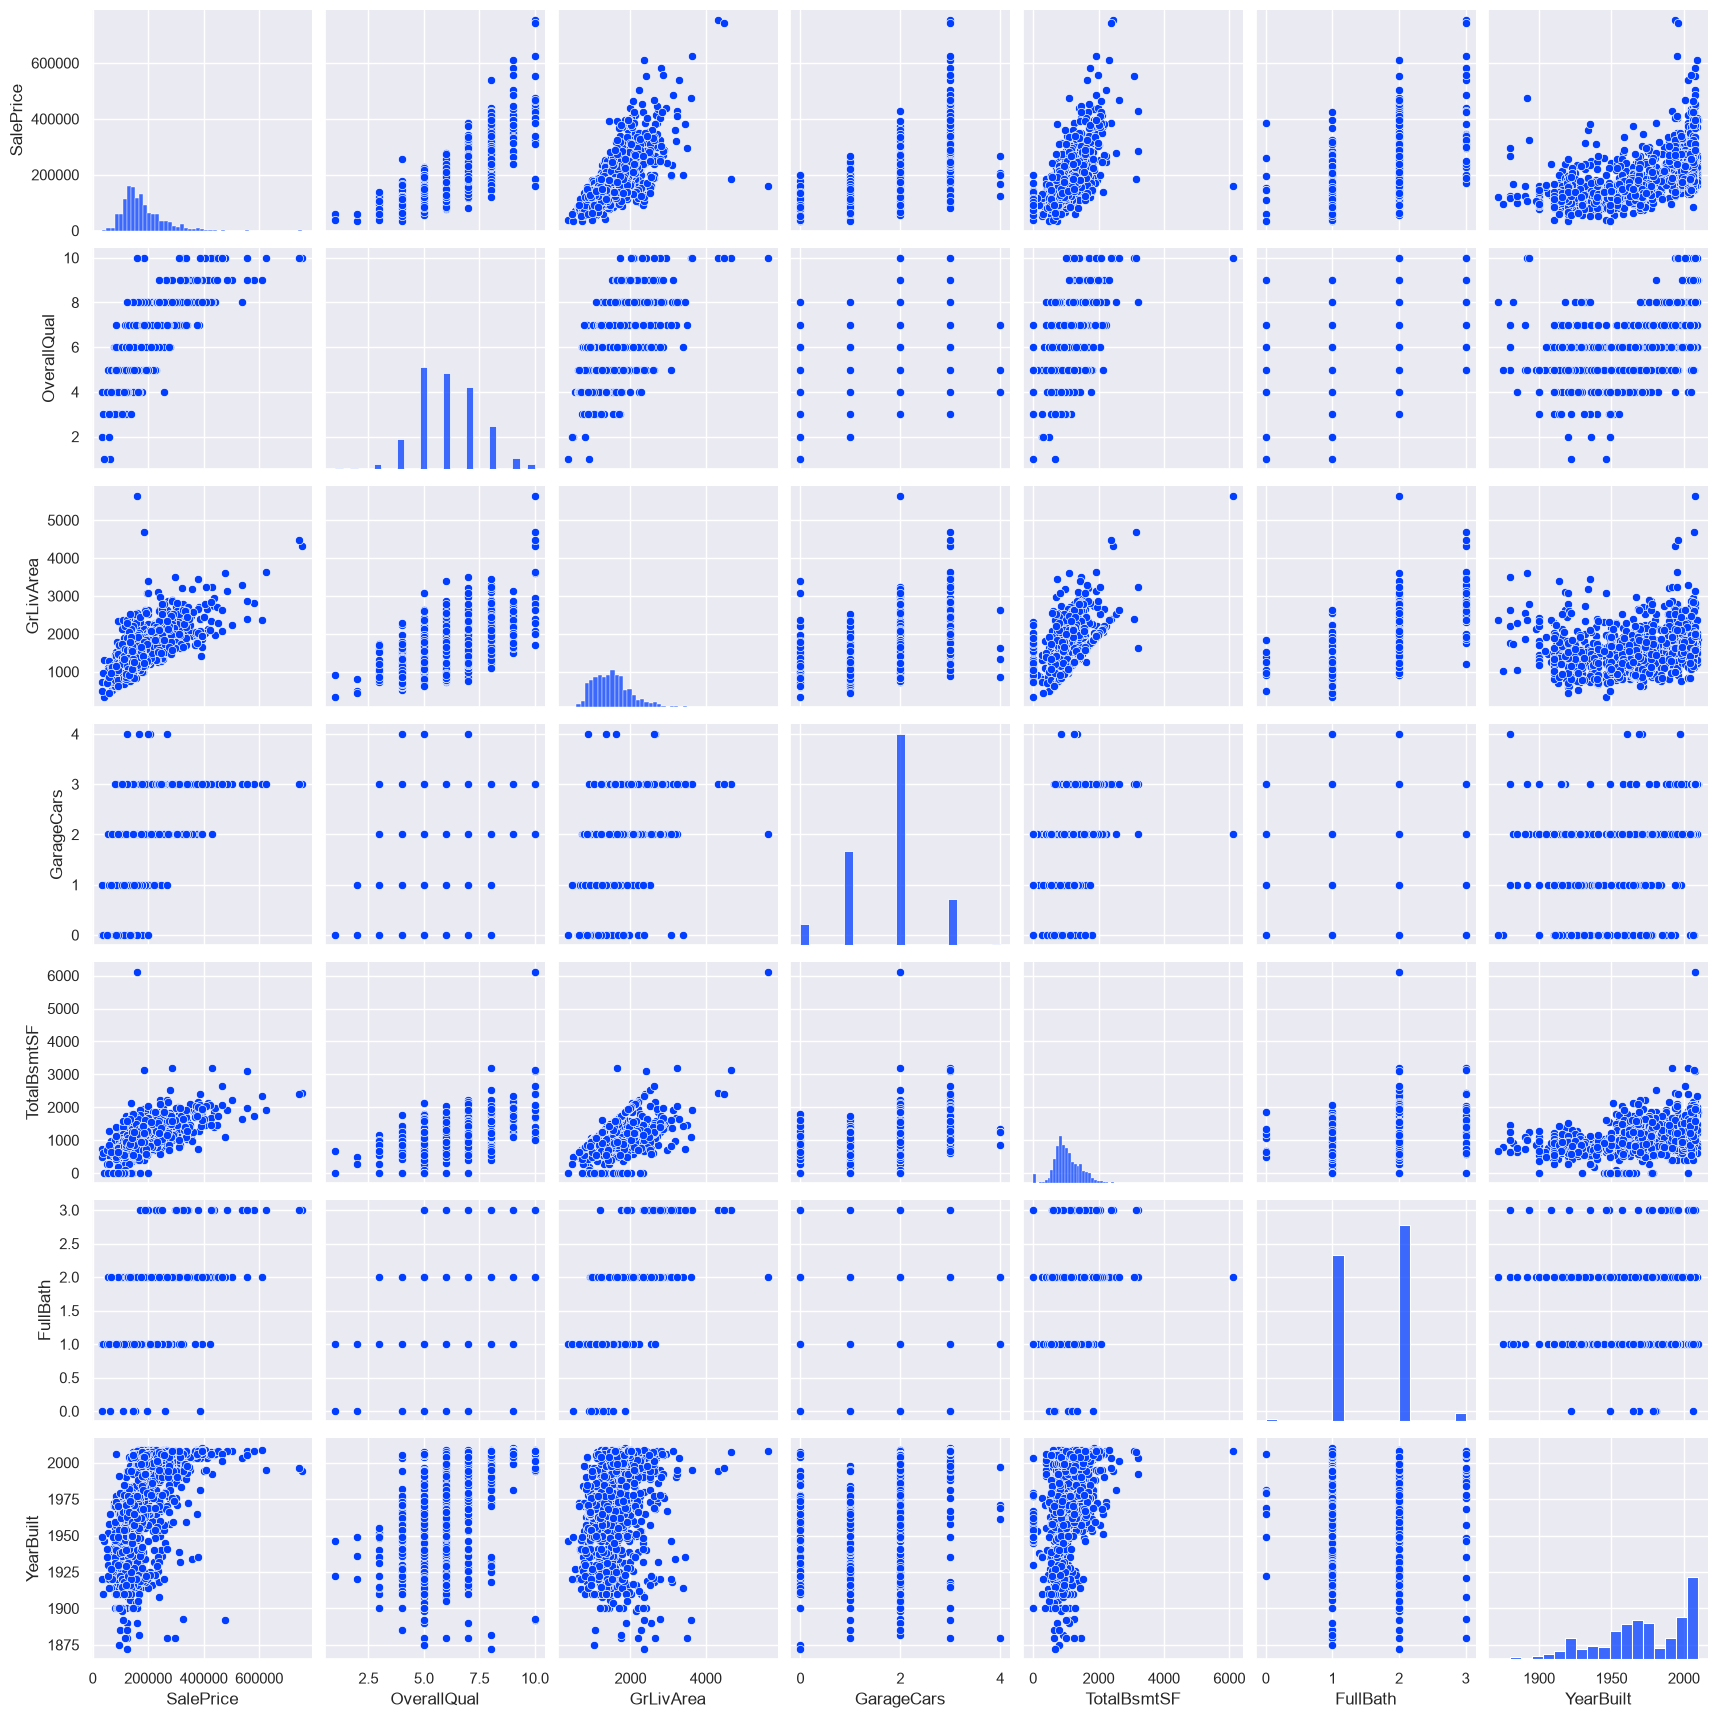

In [74]:
high_corr_feats = corrmat['SalePrice'].abs().nlargest(10).index
# Remove Twin Features:
# GarageCars - GarageArea
# TotalBsmntSF - 1sFlrSF
# GrLivArea - TotRmsAbvGrd
high_corr_feats = high_corr_feats.drop(['GarageArea', '1stFlrSF', 'TotRmsAbvGrd'])

# Pair plots
sns.pairplot(train[high_corr_feats], height=2.5)

## Missing Data

In [81]:
total_na = train.isna().sum().sort_values(ascending=False)
percent_na = (train.isna().sum() / train.isna().count()).sort_values(ascending=False)
missing_data = pd.concat([total_na, percent_na], axis=1, keys=['Total', 'Percent'])
missing_data.head(20)

,Total,Percent
PoolQC,1453,0.995205
MiscFeature,1406,0.963014
Alley,1369,0.937671
Fence,1179,0.807534
MasVnrType,872,0.597260
FireplaceQu,690,0.472603
LotFrontage,259,0.177397
GarageYrBlt,81,0.055479
GarageCond,81,0.055479
GarageType,81,0.055479


In [142]:
# Dropping missing > 15% features because they're not relevant
# Dropping GarageX features because they all have the same missing vals
# and are already covered by GarageCars
# Dropping BsmntX features because of the same reason
# Dropping MasVnrArea because it does not matter
# Dropping the only missing val from Electrical 
print(train.shape)
train = train.drop(missing_data[(missing_data.Total > 1)].index, axis=1)
print(train.shape)
train = train.drop(train.loc[train.Electrical.isna()].index)
print(train.shape)

(1460, 80)
(1460, 62)
(1459, 62)


## Outliers

In [145]:
# Standardize SalesPrice
from sklearn.preprocessing import StandardScaler

saleprice_scaled = StandardScaler().fit_transform(train[['SalePrice']])
high_outliers = saleprice_scaled[saleprice_scaled[:, 0].argsort()][:10]
low_outliers = saleprice_scaled[saleprice_scaled[:, 0].argsort()][-10:]
print('high_outliers:\n', high_outliers)
print('low_outliers:\n', low_outliers)
train['SalePriceScaled'] = saleprice_scaled

high_outliers:
 [[-1.83820775]
 [-1.83303414]
 [-1.80044422]
 [-1.78282123]
 [-1.77400974]
 [-1.62295562]
 [-1.6166617 ]
 [-1.58519209]
 [-1.58519209]
 [-1.57269236]]
low_outliers:
 [[3.82758058]
 [4.0395221 ]
 [4.49473628]
 [4.70872962]
 [4.728631  ]
 [5.06034585]
 [5.42191907]
 [5.58987866]
 [7.10041987]
 [7.22629831]]


<Axes: xlabel='GrLivArea', ylabel='SalePrice'>

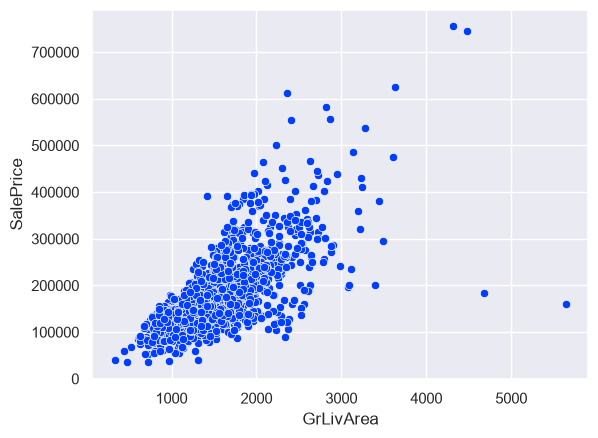

In [143]:
sns.scatterplot(train, x='GrLivArea', y='SalePrice')


In [146]:
# There are 2 outliers here on the rightmost section are problematic so remove them
train.sort_values(by='GrLivArea', ascending=False)[:2]['SalePriceScaled']
# Whereas the 2 highest ones on the SalePrice axis don't seem to be outliers
train.sort_values(by='SalePrice', ascending=False)[:2]['SalePriceScaled']
indices = train.sort_values(by='GrLivArea', ascending=False)[:2].index
train = train.drop(indices)
print(train.shape)


(1457, 63)


<Axes: xlabel='GrLivArea', ylabel='SalePrice'>

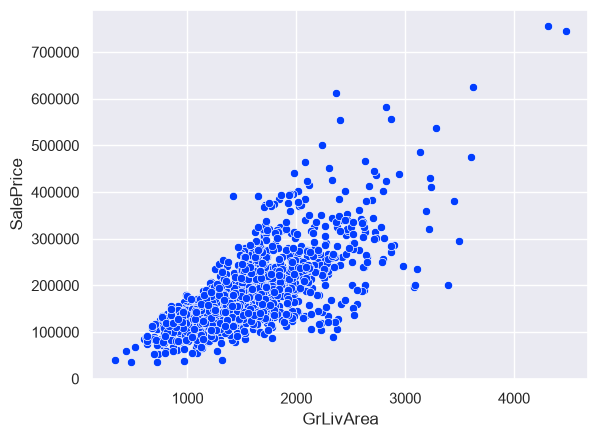

In [130]:
sns.scatterplot(train, x='GrLivArea', y='SalePrice')

<Axes: xlabel='TotalBsmtSF', ylabel='SalePrice'>

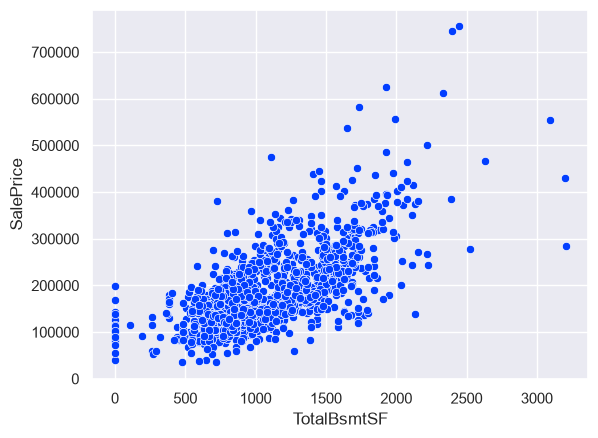

In [132]:
sns.scatterplot(train, x='TotalBsmtSF', y='SalePrice')

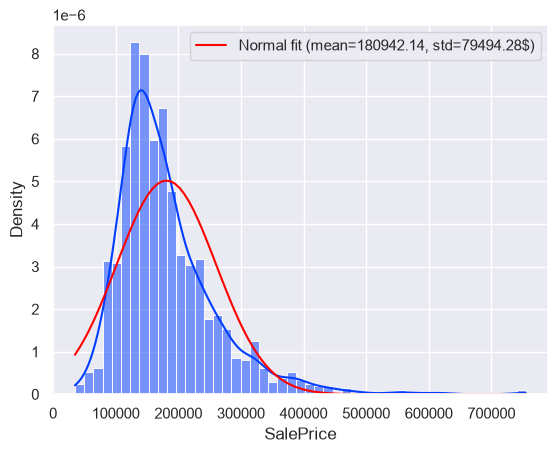

In [ ]:
from scipy.stats import norm

# Calculate normal curve 
mu, std = norm.fit(train.SalePrice)
x = np.linspace(min(train.SalePrice), max(train.SalePrice), 100)
pdf = norm.pdf(x, mu, std)

# Plot SalePrice density
sns.histplot(train, x='SalePrice', stat='density', kde=True)

# Overlay the normal curve
plt.plot(x, pdf, color='red', label=rf'Normal fit (mean={mu:.2f}, std={std:.2f}$)')
plt.legend()


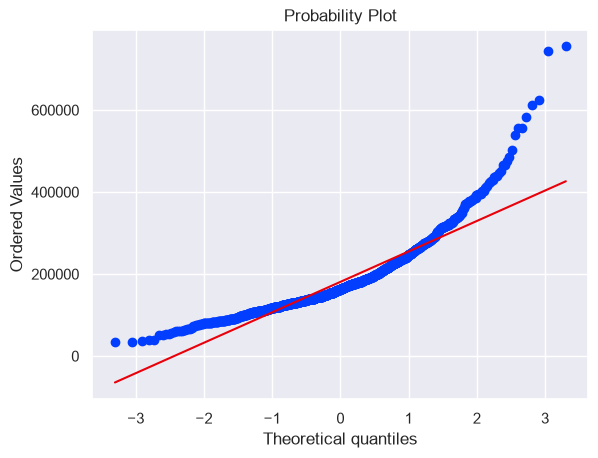

In [166]:
from scipy import stats
fig = plt.figure()
stats.probplot(train.SalePrice, plot=plt);

In [ ]:
# Applying log transform to SalePrices
train['SalePriceLog'] = np.log(train.SalePrice)

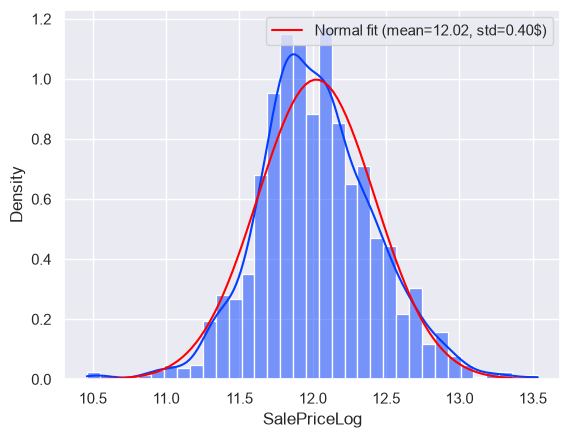

In [168]:
# Calculate normal curve 
mu, std = norm.fit(train.SalePriceLog)
x = np.linspace(min(train.SalePriceLog), max(train.SalePriceLog), 100)
pdf = norm.pdf(x, mu, std)

# Plot SalePrice density
sns.histplot(train, x='SalePriceLog', stat='density', kde=True)

# Overlay the normal curve
plt.plot(x, pdf, color='red', label=rf'Normal fit (mean={mu:.2f}, std={std:.2f}$)')
plt.legend()

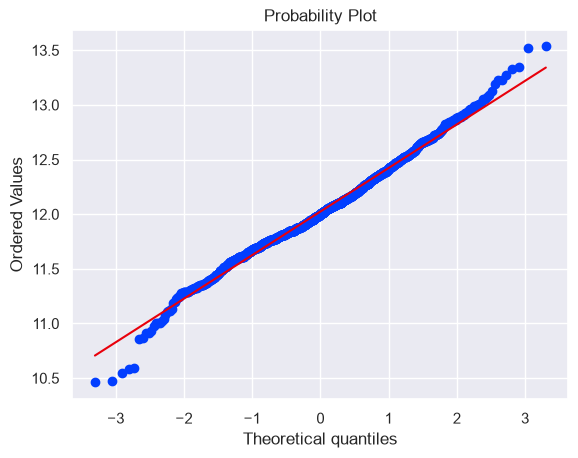

In [169]:
fig = plt.figure()
stats.probplot(train.SalePriceLog, plot=plt);

In [170]:
train.head()

,MSSubClass,MSZoning,LotArea,Street,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,...,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice,SalePriceScaled,SalePriceLog
Id,,,,,,,,,,,,,,,,,,,,,
1,60,RL,8450,Pave,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,...,0,0,0,2,2008,WD,Normal,208500,0.347042,12.247694
2,20,RL,9600,Pave,Reg,Lvl,AllPub,FR2,Gtl,Veenker,...,0,0,0,5,2007,WD,Normal,181500,0.007170,12.109011
3,60,RL,11250,Pave,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,...,0,0,0,9,2008,WD,Normal,223500,0.535860,12.317167
4,70,RL,9550,Pave,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,...,0,0,0,2,2006,WD,Abnorml,140000,-0.515225,11.849398
5,60,RL,14260,Pave,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,...,0,0,0,12,2008,WD,Normal,250000,0.869437,12.429216


In [171]:
train = pd.get_dummies(train)

In [172]:
train.head()

,MSSubClass,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,BsmtFinSF1,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,...,SaleType_ConLw,SaleType_New,SaleType_Oth,SaleType_WD,SaleCondition_Abnorml,SaleCondition_AdjLand,SaleCondition_Alloca,SaleCondition_Family,SaleCondition_Normal,SaleCondition_Partial
Id,,,,,,,,,,,,,,,,,,,,,
1,60,8450,7,5,2003,2003,706,0,150,856,...,False,False,False,True,False,False,False,False,True,False
2,20,9600,6,8,1976,1976,978,0,284,1262,...,False,False,False,True,False,False,False,False,True,False
3,60,11250,7,5,2001,2002,486,0,434,920,...,False,False,False,True,False,False,False,False,True,False
4,70,9550,7,5,1915,1970,216,0,540,756,...,False,False,False,True,True,False,False,False,False,False
5,60,14260,8,5,2000,2000,655,0,490,1145,...,False,False,False,True,False,False,False,False,True,False


In [174]:
train = train.drop('SalePriceScaled', axis=1)

# Model Training

In [177]:
SEED = 42

X = train.drop('SalePrice', axis=1)
y = train.SalePrice


In [178]:
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor

In [ ]:


X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2)


model = RandomForestRegressor(n_estimators=100, random_state=SEED, criterion='squared_error',)

model.fit(X_train, y_train)

pred = model.predict(X_val)

root_mean_squared_error(y_val, pred)


2476.542179810213

ValueError: The feature names should match those that were passed during fit.
Feature names unseen at fit time:
- Alley
- BldgType
- BsmtCond
- BsmtExposure
- BsmtFinType1
- ...
Feature names seen at fit time, yet now missing:
- BldgType_1Fam
- BldgType_2fmCon
- BldgType_Duplex
- BldgType_Twnhs
- BldgType_TwnhsE
- ...
